## Aprendizado por Reforço





In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as
import numpy as np
import time
from PIL import Image
import io
import imageio

Experimento I - Gridworld

In [ ]:
class GridWorld:
    def __init__(self, size=5):
        self.size = size
        self.start = (0, 0)
        self.goal = (size - 1, size - 1)
        self.state = self.start

    def reset(self):
        self.state = self.start
        return self._state_to_index(self.state)

    def step(self, action):
        x, y = self.state

        if action == 0:   # cima
            x = max(x - 1, 0)
        elif action == 1: # direita
            y = min(y + 1, self.size - 1)
        elif action == 2: # baixo
            x = min(x + 1, self.size - 1)
        elif action == 3: # esquerda
            y = max(y - 1, 0)

        self.state = (x, y)

        if self.state == self.goal:
            return self._state_to_index(self.state), 10, True

        return self._state_to_index(self.state), -1, False

    def _state_to_index(self, state):
        return state[0] * self.size + state[1]

def epsilon_greedy(Q, state, epsilon):
    if np.random.rand() < epsilon:
        return np.random.randint(Q.shape[1])
    return np.argmax(Q[state])

def q_learning(env, n_episodes=500, alpha=0.5, gamma=0.9):
    n_states = env.size * env.size
    n_actions = 4

    Q = np.zeros((n_states, n_actions))
    epsilon = 1.0
    episode_rewards = []
    episode_steps = []

    for _ in range(n_episodes):
        state = env.reset()
        done = False
        total_reward = 0
        steps = 0

        while not done:
            action = epsilon_greedy(Q, state, epsilon)
            next_state, reward, done = env.step(action)

            Q[state, action] += alpha * (
                reward + gamma * np.max(Q[next_state]) - Q[state, action]
            )

            state = next_state
            total_reward += reward
            steps += 1

        epsilon = max(0.05, epsilon * 0.99)

        # Acumula a Recompensa total por episódio e a média de passos por episódio
        episode_rewards.append(total_reward)
        episode_steps.append(steps)

    return Q, episode_rewards, episode_steps

def sarsa(env, n_episodes=500, alpha=0.5, gamma=0.9):
    n_states = env.size * env.size
    n_actions = 4

    Q = np.zeros((n_states, n_actions))
    epsilon = 1.0
    episode_rewards = []
    episode_steps = []

    for _ in range(n_episodes):
        state = env.reset()
        action = epsilon_greedy(Q, state, epsilon)
        done = False
        total_reward = 0
        steps = 0

        while not done:
            next_state, reward, done = env.step(action)
            next_action = epsilon_greedy(Q, next_state, epsilon)

            Q[state, action] += alpha * (
                reward + gamma * Q[next_state, next_action] - Q[state, action]
            )

            state, action = next_state, next_action
            total_reward += reward
            steps += 1

        epsilon = max(0.05, epsilon * 0.99)
        episode_rewards.append(total_reward)
        episode_steps.append(steps)

    return Q, episode_rewards, episode_steps


def render_frame(env):
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.set_xlim(-0.5, env.size - 0.5)
    ax.set_ylim(-0.5, env.size - 0.5)

    for i in range(env.size):
        ax.axhline(i - 0.5, color="gray")
        ax.axvline(i - 0.5, color="gray")

    gy, gx = env.goal
    ax.scatter(gx, env.size - 1 - gy, s=300, c="green", marker="s")

    y, x = env.state
    ax.scatter(x, env.size - 1 - y, s=200, c="red")

    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title("GridWorld")

    buf = io.BytesIO()
    plt.savefig(buf, format="png")
    plt.close(fig)
    buf.seek(0)

    return Image.open(buf)


def generate_gif(env, Q, max_steps=50):
    frames = []
    env.reset()
    done = False
    step = 0

    while not done and step < max_steps:
        frames.append(render_frame(env))

        state_idx = env._state_to_index(env.state)
        action = np.argmax(Q[state_idx])
        _, _, done = env.step(action)
        step += 1

    return frames

In [ ]:
env = GridWorld(size=5)

print("Treinando Q-Learning...")
Q_q = q_learning(env)

print("Treinando SARSA...")
Q_s = sarsa(env)

Treinando Q-Learning...
Treinando SARSA...


In [ ]:
print("Gerando GIF Q-Learning...")
frames_q = generate_gif(env, Q_q)
frames_q[0].save(
    "gridworld_qlearning.gif",
    save_all=True,
    append_images=frames_q[1:],
    duration=400,
    loop=0
)

Gerando GIF Q-Learning...


In [ ]:
print("Gerando GIF SARSA...")
frames_s = generate_gif(env, Q_s)
frames_s[0].save(
    "gridworld_sarsa.gif",
    save_all=True,
    append_images=frames_s[1:],
    duration=400,
    loop=0
)

Gerando GIF SARSA...


In [ ]:
from IPython.display import Image, display

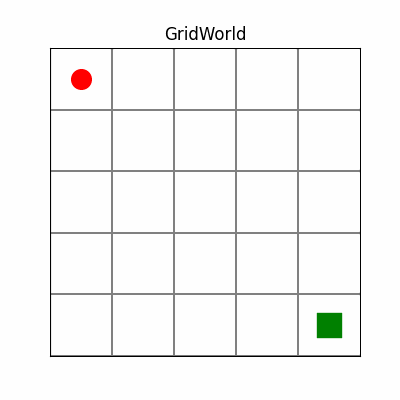

In [ ]:
display(Image(filename="gridworld_qlearning.gif"))

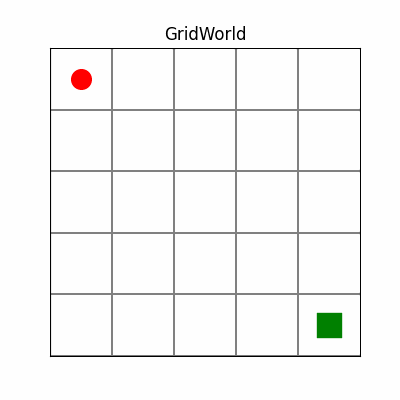

In [ ]:
display(Image(filename="gridworld_sarsa.gif"))

Experimento II - FrozenLake

In [ ]:
from IPython.display import Image, display

In [ ]:
def epsilon_greedy(Q, state, epsilon, n_actions):
    if np.random.rand() < epsilon:
        return np.random.randint(n_actions)
    return np.argmax(Q[state])

def q_learning(env, n_episodes=500, alpha=0.1, gamma=0.99):
    n_states = env.observation_space.n
    n_actions = env.action_space.n

    Q = np.zeros((n_states, n_actions))
    epsilon = 1.0
    episode_rewards = []
    episode_steps = []

    for _ in range(n_episodes):
        state, _ = env.reset()
        done = False
        total_reward = 0
        steps = 0

        while not done:
            action = epsilon_greedy(Q, state, epsilon, n_actions)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            Q[state, action] += alpha * (
                reward + gamma * np.max(Q[next_state]) - Q[state, action]
            )

            state = next_state
            total_reward += reward
            steps += 1

        epsilon = max(0.05, epsilon * 0.999)
        episode_rewards.append(total_reward)
        episode_steps.append(steps)

    return Q, episode_rewards, episode_steps

def sarsa(env, n_episodes=500, alpha=0.1, gamma=0.99):
    n_states = env.observation_space.n
    n_actions = env.action_space.n

    Q = np.zeros((n_states, n_actions))
    epsilon = 1.0
    episode_rewards = []
    episode_steps = []

    for _ in range(n_episodes):
        state, _ = env.reset()
        action = epsilon_greedy(Q, state, epsilon, n_actions)
        done = False
        total_reward = 0
        steps = 0

        while not done:
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            next_action = epsilon_greedy(Q, next_state, epsilon, n_actions)

            Q[state, action] += alpha * (
                reward + gamma * Q[next_state, next_action] - Q[state, action]
            )

            state, action = next_state, next_action
            total_reward += reward
            steps += 1

        epsilon = max(0.05, epsilon * 0.999)

        # Acumula a Recompensa total por episódio e a média de passos por episódio
        episode_rewards.append(total_reward)
        episode_steps.append(steps)

    return Q, episode_rewards, episode_steps

def generate_gif(env, Q, filename):
    frames = []
    state, _ = env.reset()
    done = False

    while not done:
        frames.append(env.render())
        action = np.argmax(Q[state])
        state, _, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

    imageio.mimsave(filename, frames, fps=2)

In [ ]:
env = gym.make(
  "FrozenLake-v1",
  is_slippery=False,
  render_mode="rgb_array"
)

print("Treinando Q-Learning...")
Q_q = q_learning(env)

print("Treinando SARSA...")
Q_s = sarsa(env)

Treinando Q-Learning...
Treinando SARSA...


In [ ]:
print("Gerando GIF Q-Learning...")
generate_gif(env, Q_q[0], "frozen_qlearning.gif")

Gerando GIF Q-Learning...


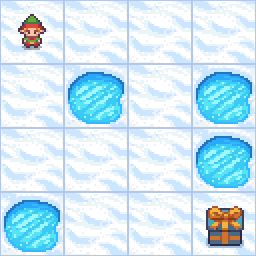

In [ ]:
display(Image(filename="frozen_qlearning.gif"))

In [ ]:
print("Gerando GIF SARSA...")
generate_gif(env, Q_s[0], "frozen_sarsa.gif")

Gerando GIF SARSA...


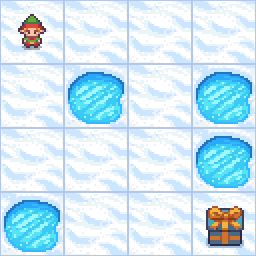

In [ ]:
display(Image(filename="frozen_sarsa.gif"))

Experimento III - Taxi

In [ ]:
def epsilon_greedy(Q, state, epsilon, n_actions):
    if np.random.rand() < epsilon:
        return np.random.randint(n_actions)
    return np.argmax(Q[state])

def q_learning(env, n_episodes=5000, alpha=0.1, gamma=0.99):
    n_states = env.observation_space.n
    n_actions = env.action_space.n

    Q = np.zeros((n_states, n_actions))
    epsilon = 1.0
    episode_rewards = []
    episode_steps = []

    for _ in range(n_episodes):
        state, _ = env.reset()
        done = False
        total_reward = 0
        steps = 0

        while not done:
            action = epsilon_greedy(Q, state, epsilon, n_actions)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            Q[state, action] += alpha * (
                reward + gamma * np.max(Q[next_state]) - Q[state, action]
            )

            state = next_state
            total_reward += reward
            steps += 1

        epsilon = max(0.05, epsilon * 0.995)

        # Acumula a Recompensa total por episódio e a média de passos por episódio
        episode_rewards.append(total_reward)
        episode_steps.append(steps)

    return Q, episode_rewards, episode_steps


def sarsa(env, n_episodes=5000, alpha=0.1, gamma=0.99):
    n_states = env.observation_space.n
    n_actions = env.action_space.n

    Q = np.zeros((n_states, n_actions))
    epsilon = 1.0
    episode_rewards = []
    episode_steps = []

    for _ in range(n_episodes):
        state, _ = env.reset()
        action = epsilon_greedy(Q, state, epsilon, n_actions)
        done = False
        total_reward = 0
        steps = 0

        while not done:
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            next_action = epsilon_greedy(Q, next_state, epsilon, n_actions)

            Q[state, action] += alpha * (
                reward + gamma * Q[next_state, next_action] - Q[state, action]
            )

            state, action = next_state, next_action
            total_reward += reward
            steps += 1

        epsilon = max(0.05, epsilon * 0.995)

        # Acumula a Recompensa total por episódio e a média de passos por episódio
        episode_rewards.append(total_reward)
        episode_steps.append(steps)

    return Q, episode_rewards, episode_steps

def generate_gif(env, Q, filename):
    frames = []
    state, _ = env.reset()
    done = False

    while not done:
        frames.append(env.render())
        action = np.argmax(Q[state])
        state, _, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

    imageio.mimsave(filename, frames, fps=3)

In [ ]:
env = gym.make("Taxi-v3", render_mode="rgb_array")

print("Treinando Q-Learning...")
Q_q = q_learning(env)

print("Treinando SARSA...")
Q_s = sarsa(env)

Treinando Q-Learning...
Treinando SARSA...


In [ ]:
print("Gerando GIF Q-Learning...")
generate_gif(env, Q_q[0], "taxi_qlearning.gif")

Gerando GIF Q-Learning...


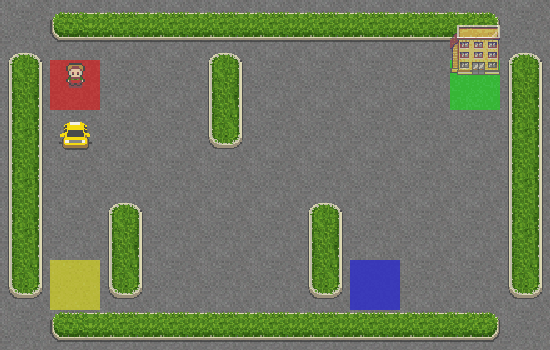

In [ ]:
display(Image(filename="taxi_qlearning.gif"))

In [ ]:
print("Gerando GIF SARSA...")
generate_gif(env, Q_s[0], "taxi_sarsa.gif")

Gerando GIF SARSA...


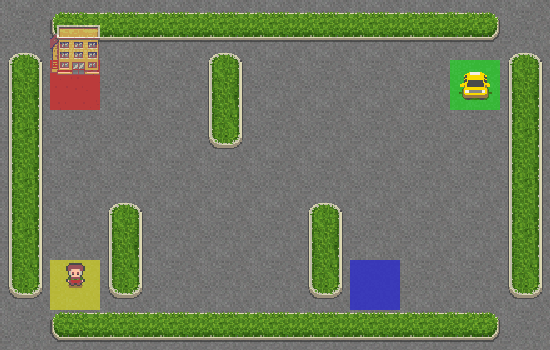

In [ ]:
display(Image(filename="taxi_sarsa.gif"))

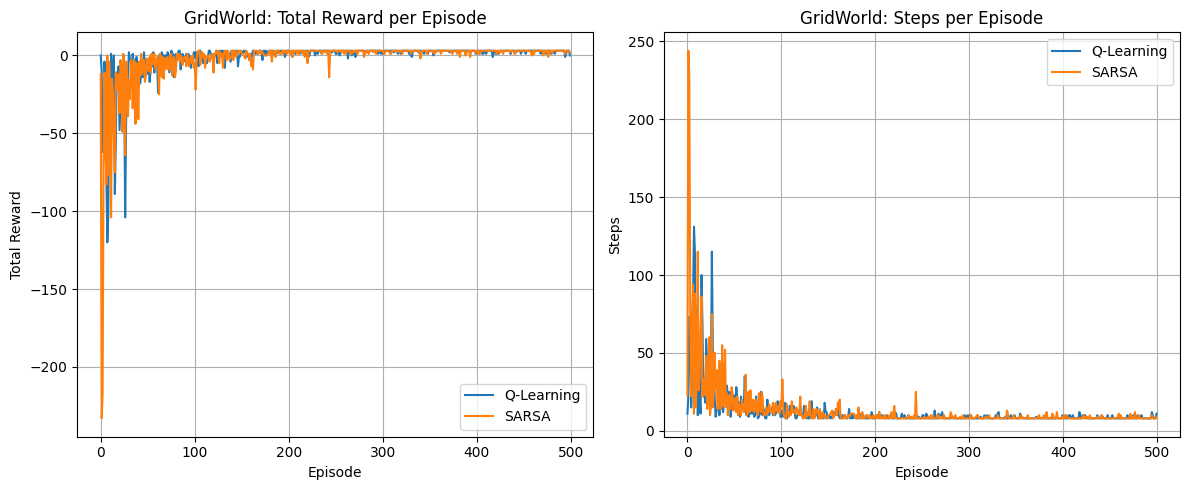

In [ ]:
plt.figure(figsize=(12, 5))

# Plot for GridWorld Total Reward per Episode
plt.subplot(1, 2, 1)
plt.plot(rewards_q_grid, label='Q-Learning')
plt.plot(rewards_s_grid, label='SARSA')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.title('GridWorld: Total Reward per Episode')
plt.legend()
plt.grid(True)

# Plot for GridWorld Steps per Episode
plt.subplot(1, 2, 2)
plt.plot(steps_q_grid, label='Q-Learning')
plt.plot(steps_s_grid, label='SARSA')
plt.xlabel('Episode')
plt.ylabel('Steps')
plt.title('GridWorld: Steps per Episode')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Para rodar com is_slippery=True

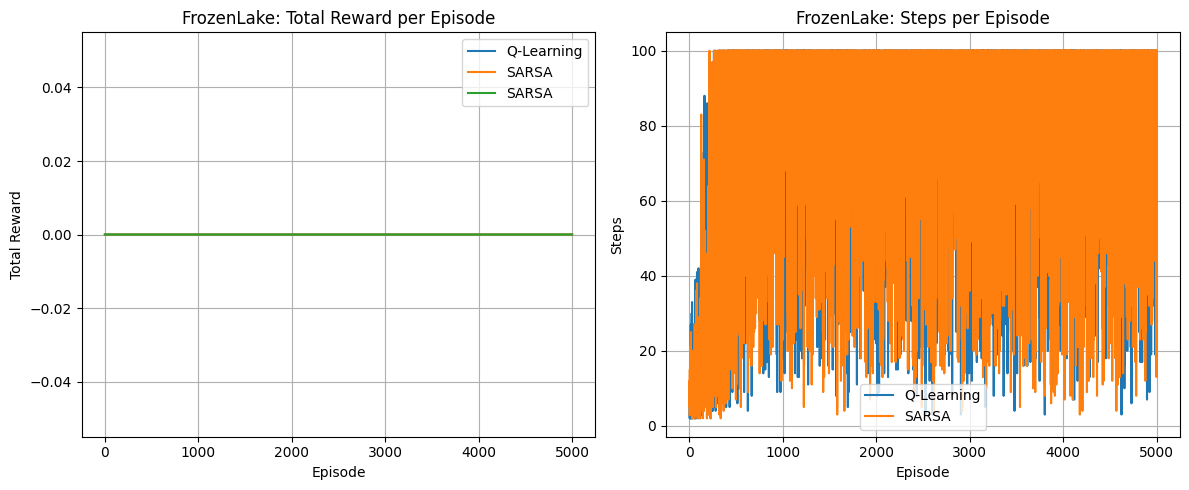

In [ ]:
plt.figure(figsize=(12, 5))

# Plot for FrozenLake Total Reward per Episode
plt.subplot(1, 2, 1)
plt.plot(rewards_q_frozenlake, label='Q-Learning')
plt.plot(rewards_s_frozenlake, label='SARSA')
plt.plot(rewards_s_frozenlake, label='SARSA')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.title('FrozenLake: Total Reward per Episode')
plt.legend()
plt.grid(True)

# Plot for FrozenLake Steps per Episode
plt.subplot(1, 2, 2)
plt.plot(steps_q_frozenlake, label='Q-Learning')
plt.plot(steps_s_frozenlake, label='SARSA')
plt.xlabel('Episode')
plt.ylabel('Steps')
plt.title('FrozenLake: Steps per Episode')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Para rodar com is_slippery=False

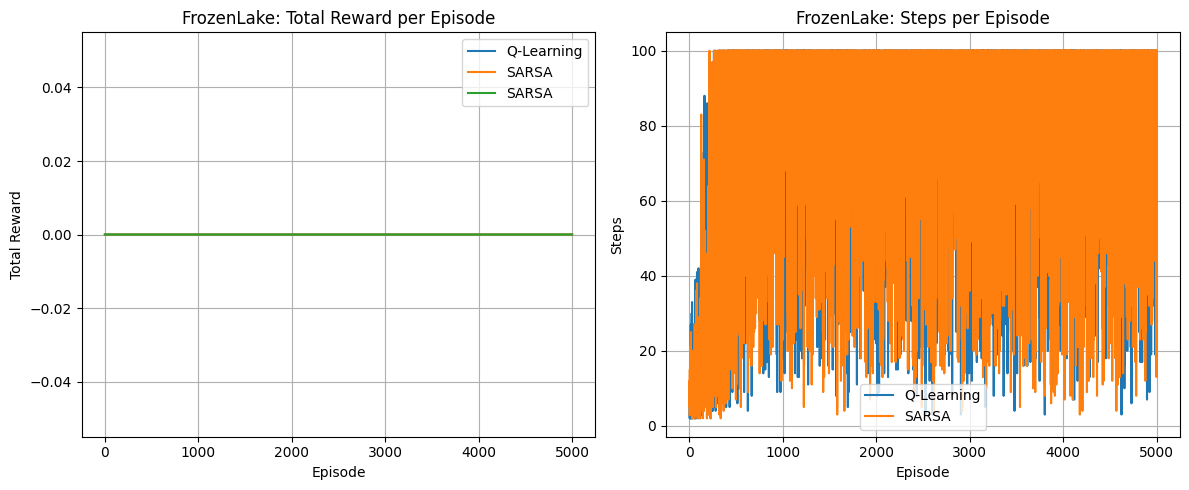

In [ ]:
plt.figure(figsize=(12, 5))

# Plot for FrozenLake Total Reward per Episode
plt.subplot(1, 2, 1)
plt.plot(rewards_q_frozenlake, label='Q-Learning')
plt.plot(rewards_s_frozenlake, label='SARSA')
plt.plot(rewards_s_frozenlake, label='SARSA')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.title('FrozenLake: Total Reward per Episode')
plt.legend()
plt.grid(True)

# Plot for FrozenLake Steps per Episode
plt.subplot(1, 2, 2)
plt.plot(steps_q_frozenlake, label='Q-Learning')
plt.plot(steps_s_frozenlake, label='SARSA')
plt.xlabel('Episode')
plt.ylabel('Steps')
plt.title('FrozenLake: Steps per Episode')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

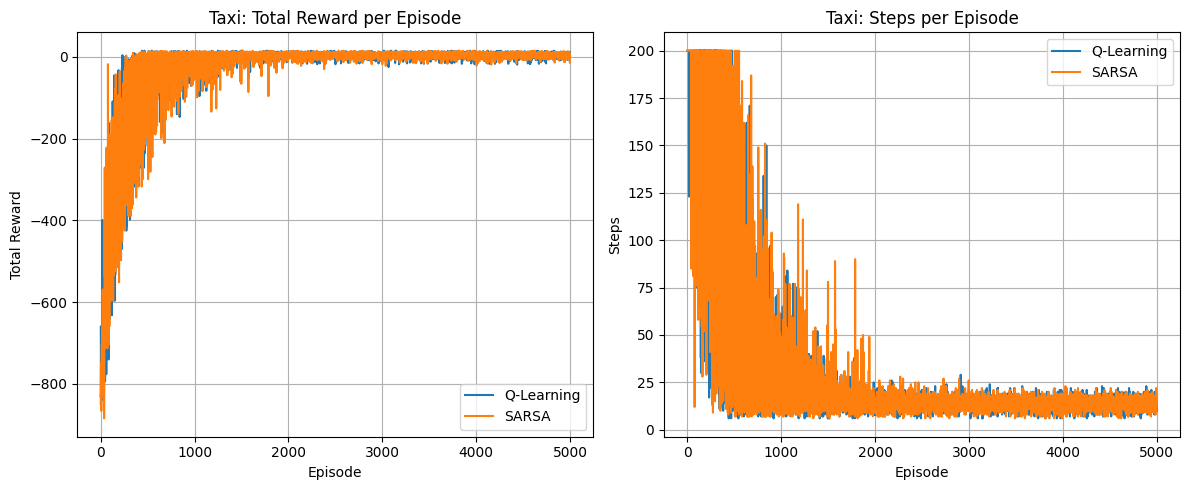

In [ ]:
plt.figure(figsize=(12, 5))

# Plot for Taxi Total Reward per Episode
plt.subplot(1, 2, 1)
plt.plot(rewards_q_taxi, label='Q-Learning')
plt.plot(rewards_s_taxi, label='SARSA')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.title('Taxi: Total Reward per Episode')
plt.legend()
plt.grid(True)

# Plot for Taxi Steps per Episode
plt.subplot(1, 2, 2)
plt.plot(steps_q_taxi, label='Q-Learning')
plt.plot(steps_s_taxi, label='SARSA')
plt.xlabel('Episode')
plt.ylabel('Steps')
plt.title('Taxi: Steps per Episode')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Compare:
* ε constante
* ε decrescente (dacay)


**Qual estratégia converge mais rápido?**

O ε decrescente (dacay) apresenta uma convergência mais eficaz para a política ótima a longo prazo. Mesmo o ε constante conseguindo atingir resultados iniciais mais rábido, o decaimento garante que o agente explore o espaço de estados de forma abrangenteno início do treino e refine esse conhecimento conforme a taxa de exploração diminui, assim, evitando convergência prematura para soluções sub-ótimas.


**Qual apresenta maior estabilidade?**

O ε decrescente (decay) proporciona maior estabilidade de desempenho. Em ambientes com ε constante, a manutenção de uma taxa fixa de açõesaleatórias impede que a recompensa total se estabilize, gerando um ruído permanente nos gráficos de aprendizado. Com o dacay, a redução gradual da aleatoriedade permite que o agente execute a política aprendida de forma quase determiníestica no final do treino, que resulta em uma cuurva de recompensa alta e estável.


**Há diferenças entre os ambientes?**

Sim, pois a necessidade de exploração varia conforme a complexidade e a natureza do ambiente

1. Impacto da Estocasticidade (is_slippery)

* Ambiente Determinístico (is_slippery = False):

* * O aprendizado é linear e rápido. Como o agente sempre termina na posição pretendida, o número de episódios para encontrar o objetivo é baixo e a recompensa estabiliza rapidamente no valor máximo.

* * Ambiente Estocástico (is_slippery = True): A convergência é mais lenta e os gráficos de recompensa apresentam alta variância. Mesmo que a política final pareça idêntica, o agente leva mais tempo para aprender porque o resultado das ações é incerto, exigindo mais exploração para consolidar os valores da matriz.

* Diferença de Comportamento:
* * Q-learning vs SARSAQ-learning (Off-policy): O algoritmo foca na política ótima teórica através do operador $max_{a'} Q(s', a')$. Em ambientes estocásticos, isso o torna mais "agressivo", pois ele assume que sempre conseguirá tomar a melhor ação futura, ignorando os riscos de deslizes aleatórios para buracos durante o aprendizado.
* * SARSA (On-policy): O aprendizado é baseado na política efetivamente executada ($Q(s', a')$). Isso faz com que o SARSA aprenda uma política mais "conservadora", preferindo caminhos que o mantenham longe das bordas dos buracos (H), já que ele considera o risco real de escorregar enquanto ainda está explorando o ambiente.

## Ambiente: Gridworld

O agente aprende o caminho mais curto da posição inicial (0,0) até o objetivo (G). O comportamento esperado é uma sequência de movimentos para a direita e para baixo até alcançar a célula de objetivo, demonstrando que o algoritmo minimizou a penalidade de -1 por passo.

## Ambiente: Frozen Lake
* is_slippery = False: O agente segue um caminho direto e determinístico até o objetivo.
* is_slippery = True: O comportamento do agente muda para mitigar o risco de deslizes. O agente pode escolher ações que parecem "erradas" (como tentar andar contra uma parede) para garantir que, se escorregar, não caia em um buraco, priorizando a segurança em vez da velocidade.

## Ambiente: Taxi

O agente demonstra um planejamento sequencial complexo:

1. Navega até a posição do passageiro.

2. Executa a ação de Pickup (coleta).


3. Navega do ponto de coleta até o destino final.

4. Executa a ação de entrega. O comportamento indica que o agente aprendeu a evitar ações inválidas (penalidade de -10) e a buscar a rota mais eficiente (penalidade de -1 por passo).

## Por que o Q-learning pode ser instável em ambientes estocásticos?

O Q-learning é um algoritmo off-policy que utiliza o operador de maximização ($max_{a^{\prime}}Q(s^{\prime},a^{\prime})$) para atualizar seus valores de estado-ação. Em ambientes estocásticos, como o Frozen Lake com a configuração is_slippery = True, as transições entre estados e as recompensas possuem um componente de incerteza. O uso do valor máximo para a estimativa futura pode levar a uma superestimação sistemática dos valores de $Q$. Como o algoritmo assume que sempre tomará a melhor ação possível no próximo passo, ele ignora a probabilidade de que, devido à natureza aleatória do ambiente, o agente acabe em um estado indesejado (como um buraco), o que gera oscilações e instabilidade na convergência da política.

## Qual ambiente foi mais difícil?  
Por quê? O ambiente Taxi é considerado o mais difícil entre os propostos. Diferente do Gridworld ou do Frozen Lake, que possuem espaços de estados menores e objetivos diretos de navegação , o Taxi apresenta um espaço de estados composto por 500 combinações. Além disso, ele exige o aprendizado de uma hierarquia lógica de ações: o agente deve primeiro navegar até o passageiro, realizar o pickup, navegar até o destino e, finalmente, realizar o dropoff. A estrutura de recompensa, que penaliza ações inválidas com -10, torna o aprendizado inicial mais penoso para o agente antes que ele descubra a sequência correta de sucesso.

## Qual o papel da exploração na convergência?
A exploração, geralmente implementada via política $\epsilon$-greedy, é fundamental para garantir que o agente visite uma variedade suficiente de pares estado-ação antes de convergir para uma política definitiva. Sem uma exploração adequada, o agente pode sofrer de convergência prematura, ficando preso em uma política sub-ótima (máximo local) por nunca ter descoberto caminhos que levam a recompensas maiores a longo prazo12. Estratégias como o $\epsilon$ decrescente (decay) permitem que o agente explore intensamente o ambiente no início do treinamento e, gradualmente, passe a explorar menos conforme o conhecimento sobre os valores de $Q$ se torna mais sólido, resultando em uma política estável e otimizada ao final do processo.